In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

In [21]:
from pathlib import Path

downloads = Path.home() / "Downloads"

files = list(downloads.rglob("housing.csv"))

print(files)

[WindowsPath('C:/Users/alex1/Downloads/BigTech/housing.csv'), WindowsPath('C:/Users/alex1/Downloads/housing/housing.csv')]


In [56]:
housing = pd.read_csv("/Users/alex1/Downloads/BigTech/housing_tech_hubs_and_nearby.csv")

print("Housing Dataset Shape:")
print(housing.shape)

print("\nFirst Five Rows:")
print(housing.head())

print("\nColumn Names:")
print(housing.columns.tolist())

print("\nDataset Information:")
housing.info()

print("\nMissing Values:")
print(housing.isnull().sum())

print("\nSummary Statistics:")
print(housing.describe())

Housing Dataset Shape:
(21, 329)

First Five Rows:
   RegionID  SizeRank RegionName RegionType StateName State  \
0      6181         0   New York       city        NY    NY   
1     38128         9     Dallas       city        TX    TX   
2     10221        10     Austin       city        TX    TX   
3     33839        11   San Jose       city        CA    CA   
4     16037        24    Seattle       city        WA    WA   

                                   Metro          CountyName  2000-01-31  \
0  New York-Newark-Jersey City, NY-NJ-PA       Queens County  240,841.23   
1        Dallas-Fort Worth-Arlington, TX       Dallas County   97,512.74   
2       Austin-Round Rock-Georgetown, TX       Travis County  195,572.70   
3     San Jose-Sunnyvale-Santa Clara, CA  Santa Clara County  313,195.15   
4            Seattle-Tacoma-Bellevue, WA         King County  256,562.09   

   2000-02-29  2000-03-31  2000-04-30  2000-05-31  2000-06-30  2000-07-31  \
0  242,122.94  243,435.00  245,959.6

In [57]:
wage_files = sorted(glob.glob("OFLC_BigTech_Wages_*.csv"))

wage_dfs = []

for file in wage_files:

    year = int(
        os.path.basename(file)
        .replace("OFLC_BigTech_Wages_", "")
        .replace(".csv", "")
    )

    df = pd.read_csv(file, low_memory=False)

    df["Year"] = year

    wage_dfs.append(df)

wages = pd.concat(wage_dfs, ignore_index=True)

print("Combined Wage Dataset Shape:")
print(wages.shape)

print("\nFirst Five Rows:")
print(wages.head())

print("\nColumn Names:")
print(wages.columns.tolist())

print("\nDataset Information:")
wages.info()

print("\nMissing Values:")
print(wages.isnull().sum())

print("\nSummary Statistics:")
print(wages.describe(include="all"))

Combined Wage Dataset Shape:
(21395, 18)

First Five Rows:
  Company        LCA_CASE_EMPLOYER_NAME               LCA_CASE_JOB_TITLE  \
0     AMD  ADVANCED MICRO DEVICES, INC.                PROGRAM MANAGER 1   
1     AMD  ADVANCED MICRO DEVICES, INC.  PRODUCT DEVELOPMENT ENGINEER II   
2  Micron       MICRON TECHNOLOGY, INC.                     CAD ENGINEER   
3  Micron       MICRON TECHNOLOGY, INC.              ASIC DESIGN MANAGER   
4  Micron       MICRON TECHNOLOGY, INC.              ASIC DESIGN MANAGER   

                        LCA_CASE_SOC_NAME      City  LCA_CASE_WAGE_RATE_FROM  \
0                    Industrial Engineers    Austin                88,707.00   
1  Electronics Engineers, Except Computer    Austin                63,357.00   
2  Electronics Engineers, Except Computer  San Jose               108,000.00   
3  Electronics Engineers, Except Computer  San Jose               126,351.00   
4  Electronics Engineers, Except Computer  San Jose               126,351.00   

  L

In [58]:
# Identify monthly housing columns
date_columns = [
    col for col in housing.columns
    if str(col).startswith(tuple(str(y) for y in range(2009, 2026)))
]

# Convert housing data from wide to long format
housing_long = housing.melt(
    id_vars=["RegionName", "State", "Metro"],
    value_vars=date_columns,
    var_name="Date",
    value_name="Housing_Value"
)

# Convert dates
housing_long["Date"] = pd.to_datetime(
    housing_long["Date"]
)

# Extract year
housing_long["Year"] = housing_long["Date"].dt.year

# Convert housing values to numeric
housing_long["Housing_Value"] = pd.to_numeric(
    housing_long["Housing_Value"],
    errors="coerce"
)

# Remove missing housing values
housing_long = housing_long.dropna(
    subset=["Housing_Value"]
)

# Calculate average annual housing values
housing_annual = (
    housing_long
    .groupby(["RegionName", "State", "Year"], as_index=False)
    ["Housing_Value"]
    .mean()
)

print(housing_annual.head())

  RegionName State  Year  Housing_Value
0     Austin    TX  2009     227,938.38
1     Austin    TX  2010     225,622.98
2     Austin    TX  2011     219,468.48
3     Austin    TX  2012     225,631.17
4     Austin    TX  2013     252,283.41


In [73]:
# Display column names
print(wages.columns.tolist())

# Function to identify columns
def find_column(df, candidates):
    lookup = {
        col.lower().strip(): col
        for col in df.columns
    }

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    raise ValueError(
        f"Could not find any of these columns: {candidates}"
    )


# Identify city column
city_col = find_column(
    wages,
    ["Worksite_City", "WORKSITE_CITY", "City", "CITY"]
)

# Identify annual wage column
wage_col = find_column(
    wages,
    ["Annual_Wage"]
)


# Clean city names
wages["City_Clean"] = (
    wages[city_col]
    .astype(str)
    .str.strip()
    .str.title()
)


# Clean annual wages
wages["Annual_Wage"] = pd.to_numeric(
    wages[wage_col]
    .astype(str)
    .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)


# Remove missing values
wages = wages.dropna(
    subset=["Annual_Wage", "City_Clean"]
)


# Remove invalid wages
wages = wages[
    wages["Annual_Wage"] > 0
].copy()


# Filter for the five Big Tech cities
tech_cities = [
    "Seattle",
    "San Jose",
    "New York",
    "Austin",
    "Dallas"
]

wages_hubs = wages[
    wages["City_Clean"].isin(tech_cities)
].copy()


# Display results
print("Cleaned Big Tech Wage Dataset:")
print(wages_hubs.head())

print("\nDataset Shape:")
print(wages_hubs.shape)

print("\nCities Included:")
print(wages_hubs["City_Clean"].unique())

print("\nMissing Values:")
print(wages_hubs.isnull().sum())

['Company', 'LCA_CASE_EMPLOYER_NAME', 'LCA_CASE_JOB_TITLE', 'LCA_CASE_SOC_NAME', 'City', 'LCA_CASE_WAGE_RATE_FROM', 'LCA_CASE_WAGE_RATE_UNIT', 'Annual_Wage', 'Year', 'PW_UNIT_1', 'EMPLOYER_NAME', 'JOB_TITLE', 'SOC_NAME', 'WAGE_RATE_OF_PAY_FROM', 'WAGE_UNIT_OF_PAY', 'SOC_TITLE', 'WAGE_RATE_OF_PAY_FROM_1', 'WAGE_UNIT_OF_PAY_1']
Cleaned Big Tech Wage Dataset:
  Company        LCA_CASE_EMPLOYER_NAME               LCA_CASE_JOB_TITLE  \
0     AMD  ADVANCED MICRO DEVICES, INC.                PROGRAM MANAGER 1   
1     AMD  ADVANCED MICRO DEVICES, INC.  PRODUCT DEVELOPMENT ENGINEER II   
2  Micron       MICRON TECHNOLOGY, INC.                     CAD ENGINEER   
3  Micron       MICRON TECHNOLOGY, INC.              ASIC DESIGN MANAGER   
4  Micron       MICRON TECHNOLOGY, INC.              ASIC DESIGN MANAGER   

                        LCA_CASE_SOC_NAME      City  LCA_CASE_WAGE_RATE_FROM  \
0                    Industrial Engineers    Austin                88,707.00   
1  Electronics Engineers

In [74]:
# Calculate annual wage statistics by city
wage_annual = (
    wages_hubs
    .groupby(["City_Clean", "Year"], as_index=False)
    .agg(
        Median_Wage=("Annual_Wage", "median"),
        Mean_Wage=("Annual_Wage", "mean"),
        Min_Wage=("Annual_Wage", "min"),
        Max_Wage=("Annual_Wage", "max"),
        Wage_Records=("Annual_Wage", "count")
    )
)

# Display results
print(wage_annual.head(20))

   City_Clean  Year  Median_Wage    Mean_Wage   Min_Wage       Max_Wage  \
0      Austin  2009    81,120.00   105,214.52  63,357.00     525,000.00   
1      Austin  2010    74,781.00    79,257.51  56,381.00     200,087.00   
2      Austin  2011    84,344.00    83,359.04  49,660.00     140,000.00   
3      Austin  2012    80,000.00    87,411.75  51,355.20     493,000.00   
4      Austin  2013    80,000.00    84,705.93  51,293.00     200,087.00   
5      Austin  2014    84,900.00    88,567.42  66,123.00     140,000.00   
6      Austin  2015    86,507.00    92,226.42  64,542.00     153,000.00   
7      Austin  2016    95,000.00    96,430.35  41,766.00     175,000.00   
8      Austin  2017    98,800.00    97,761.48  43,638.00     189,000.00   
9      Austin  2018   108,722.00   111,978.45  57,554.00     220,000.00   
10     Austin  2019   113,097.00   114,146.02  57,596.00     210,000.00   
11     Austin  2020   140,000.00   141,160.18  69,118.00     241,134.40   
12     Austin  2021   142

Housing Records: 85
Wage Records: 21395

Housing Cities:
['Austin' 'Dallas' 'New York' 'San Jose' 'Seattle']

Wage Cities:
['Austin' 'San Jose' 'Seattle' 'New York' 'Dallas']
Annual Big Tech Wage Summary:
  City_Clean  Year  Median_Wage  Mean_Wage  Min_Wage   Max_Wage  Wage_Records
0     Austin  2009    81,120.00 105,214.52 63,357.00 525,000.00            27
1     Austin  2010    74,781.00  79,257.51 56,381.00 200,087.00           120
2     Austin  2011    84,344.00  83,359.04 49,660.00 140,000.00           124
3     Austin  2012    80,000.00  87,411.75 51,355.20 493,000.00           156
4     Austin  2013    80,000.00  84,705.93 51,293.00 200,087.00           187


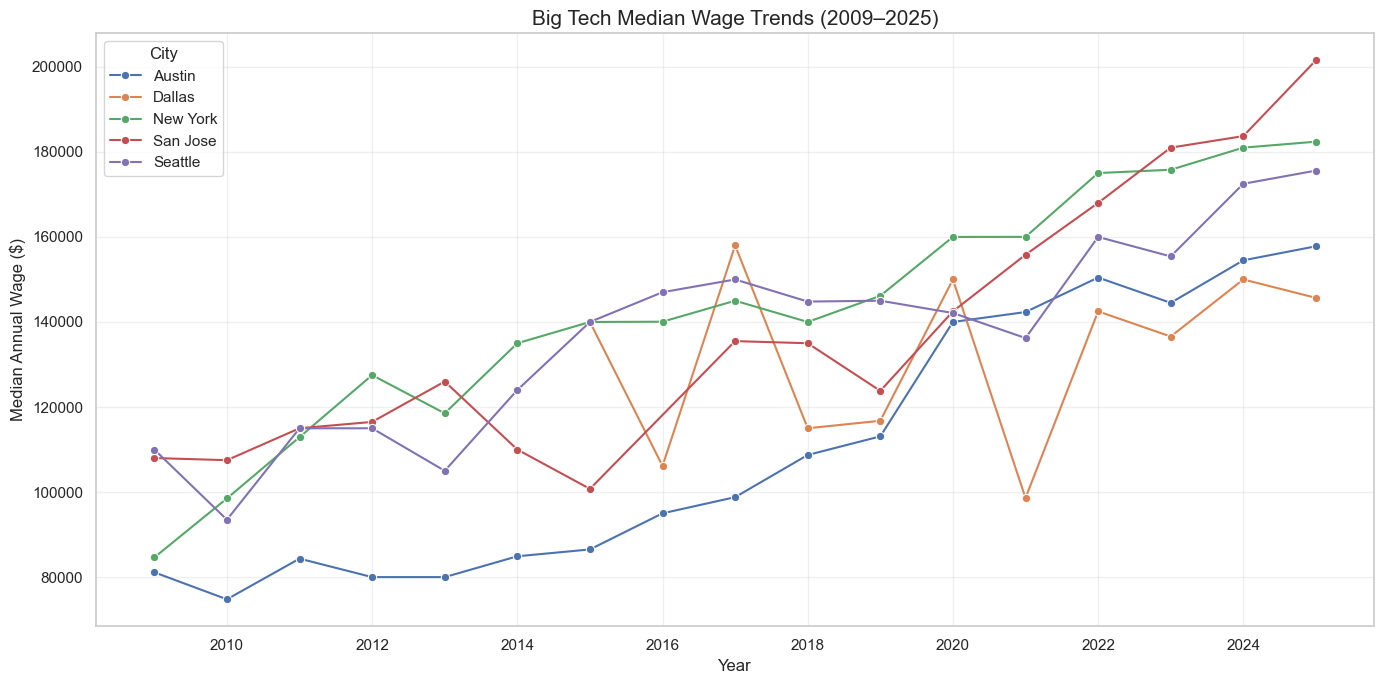

In [78]:
# Define the five major Big Tech hubs
tech_hubs = {
    "San Jose": "CA",
    "Seattle": "WA",
    "Austin": "TX",
    "New York": "NY",
    "Dallas": "TX"
}

# Get list of tech hub cities
hub_cities = list(tech_hubs.keys())


# Filter housing data using city AND state
housing_hubs = housing_annual[
    housing_annual.apply(
        lambda row: tech_hubs.get(row["RegionName"]) == row["State"],
        axis=1
    )
].copy()


# Filter Big Tech wage data using CITY ONLY
# Wage dataset does not contain a State column
wages_hubs = wages[
    wages["City_Clean"].isin(hub_cities)
].copy()


# Display results
print("Housing Records:", len(housing_hubs))
print("Wage Records:", len(wages_hubs))

print("\nHousing Cities:")
print(housing_hubs["RegionName"].unique())

print("\nWage Cities:")
print(wages_hubs["City_Clean"].unique())

# Display the first five rows
print("Annual Big Tech Wage Summary:")
print(wage_annual.head())

# Create line chart
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=wage_annual,
    x="Year",
    y="Median_Wage",
    hue="City_Clean",
    marker="o"
)

# Chart formatting
plt.title(
    "Big Tech Median Wage Trends (2009–2025)",
    fontsize=15
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Median Annual Wage", fontsize=12)

plt.legend(title="City")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

                 mean     median        min          max
RegionName                                              
San Jose   841,817.01 764,613.26 409,318.08 1,389,157.11
New York   621,323.18 639,959.53 450,671.97   792,575.16
Seattle    610,588.40 636,106.63 355,803.75   871,888.81
Austin     379,211.81 356,708.20 219,468.48   638,500.57
Dallas     198,876.20 189,272.25 104,136.64   324,233.67


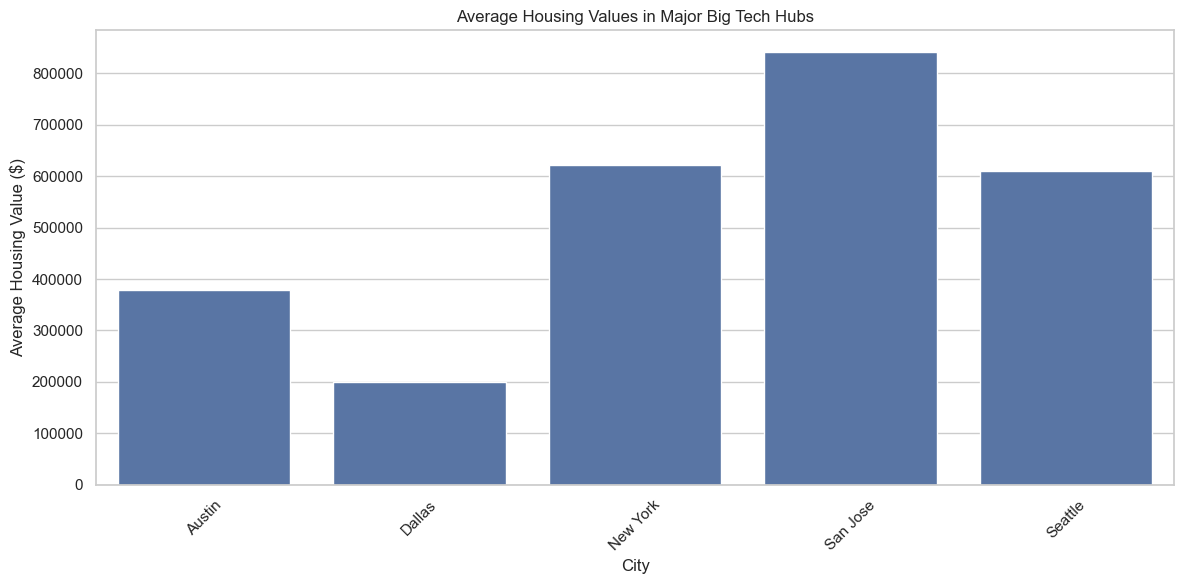

In [76]:
housing_summary = (
    housing_hubs
    .groupby("RegionName")["Housing_Value"]
    .agg(["mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

print(housing_summary)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=housing_hubs,
    x="RegionName",
    y="Housing_Value",
    estimator=np.mean,
    errorbar=None
)

plt.title("Average Housing Values in Major Big Tech Hubs")
plt.xlabel("City")
plt.ylabel("Average Housing Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

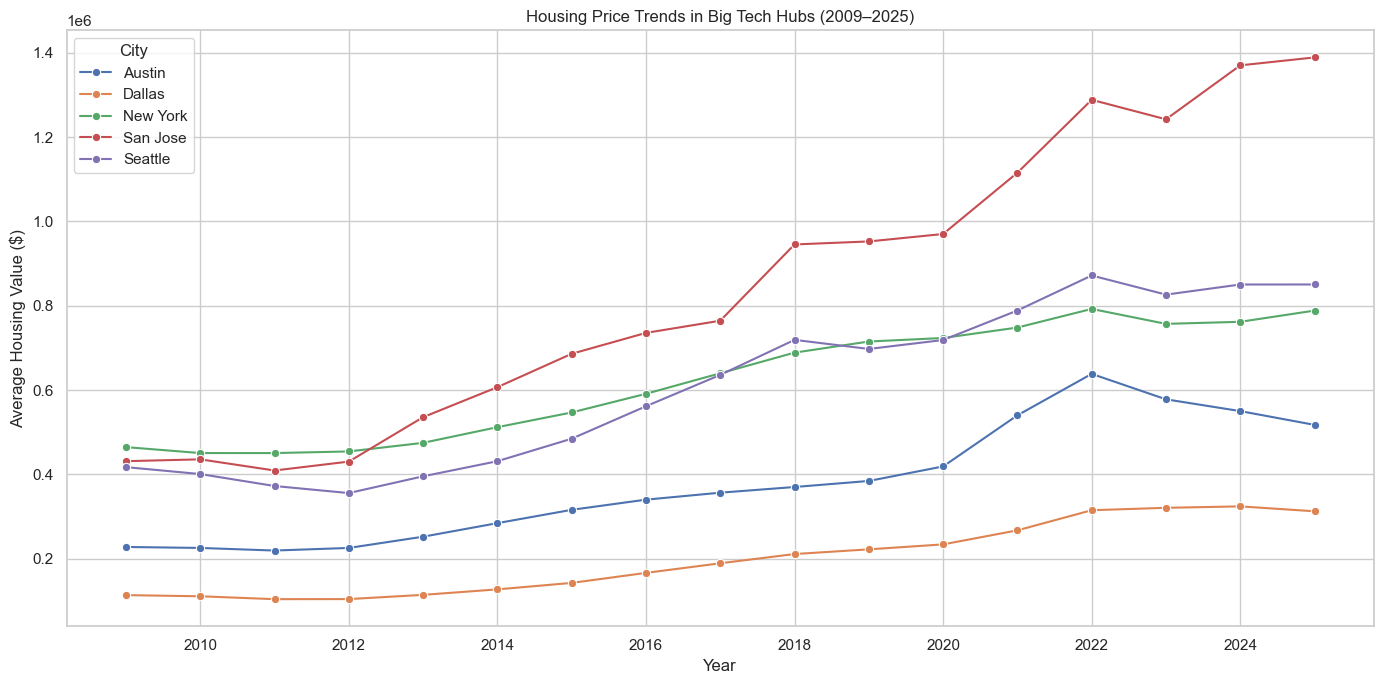

In [77]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=housing_hubs,
    x="Year",
    y="Housing_Value",
    hue="RegionName",
    marker="o"
)

plt.title("Housing Price Trends in Big Tech Hubs (2009–2025)")
plt.xlabel("Year")
plt.ylabel("Average Housing Value")

plt.legend(title="City")
plt.tight_layout()
plt.show()

In [79]:
# Merge housing and Big Tech wage datasets
# Match using City and Year

merged = pd.merge(
    housing_hubs,
    wage_annual,
    left_on=["RegionName", "Year"],
    right_on=["City_Clean", "Year"],
    how="inner",
    validate="one_to_one"
)

# Display merged dataset shape
print("Merged Dataset Shape:")
print(merged.shape)

# Display first five rows
print("\nFirst Five Rows:")
print(merged.head())

# Check missing values
print("\nMissing Values:")
print(merged.isnull().sum())

# Verify cities included
print("\nCities Included:")
print(merged["RegionName"].unique())

# Verify years included
print("\nYears Included:")
print(sorted(merged["Year"].unique()))

Merged Dataset Shape:
(78, 10)

First Five Rows:
  RegionName State  Year  Housing_Value City_Clean  Median_Wage  Mean_Wage  \
0     Austin    TX  2009     227,938.38     Austin    81,120.00 105,214.52   
1     Austin    TX  2010     225,622.98     Austin    74,781.00  79,257.51   
2     Austin    TX  2011     219,468.48     Austin    84,344.00  83,359.04   
3     Austin    TX  2012     225,631.17     Austin    80,000.00  87,411.75   
4     Austin    TX  2013     252,283.41     Austin    80,000.00  84,705.93   

   Min_Wage   Max_Wage  Wage_Records  
0 63,357.00 525,000.00            27  
1 56,381.00 200,087.00           120  
2 49,660.00 140,000.00           124  
3 51,355.20 493,000.00           156  
4 51,293.00 200,087.00           187  

Missing Values:
RegionName       0
State            0
Year             0
Housing_Value    0
City_Clean       0
Median_Wage      0
Mean_Wage        0
Min_Wage         0
Max_Wage         0
Wage_Records     0
dtype: int64

Cities Included:
['Austin' 

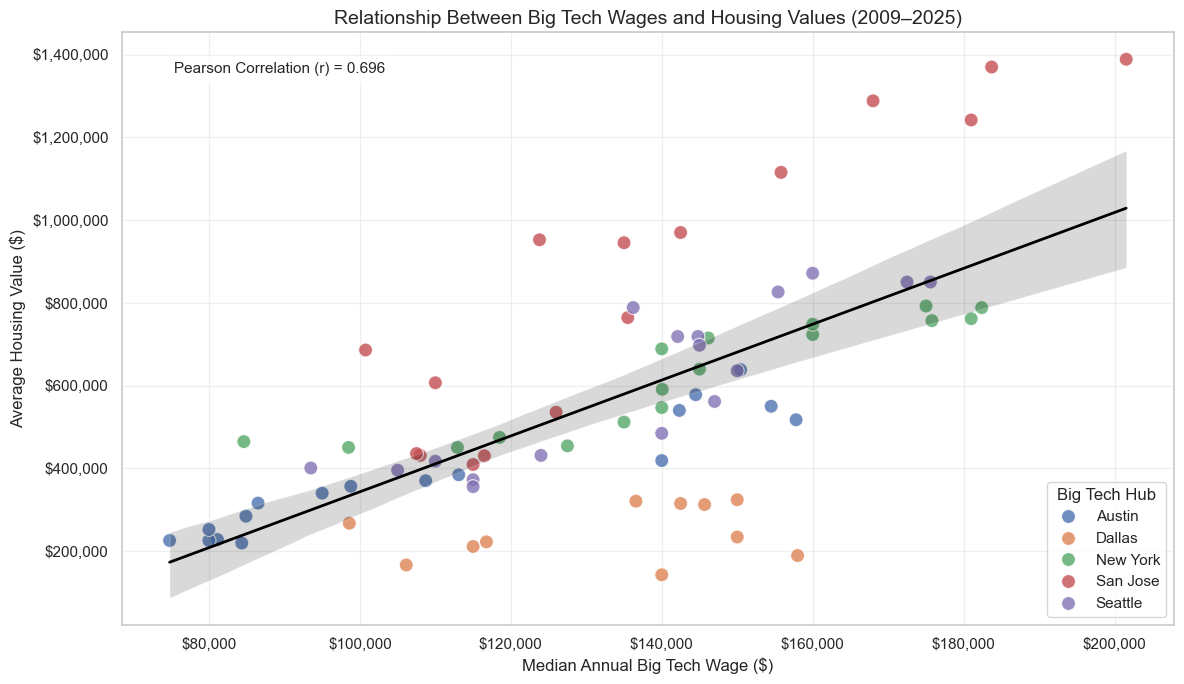

Pearson Correlation: 0.696


In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Remove missing values
plot_data = merged.dropna(
    subset=["Median_Wage", "Housing_Value"]
)

# Calculate Pearson correlation
correlation = plot_data["Median_Wage"].corr(
    plot_data["Housing_Value"]
)

# Create scatterplot
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_data,
    x="Median_Wage",
    y="Housing_Value",
    hue="RegionName",
    s=100,
    alpha=0.8
)

# Add regression line
sns.regplot(
    data=plot_data,
    x="Median_Wage",
    y="Housing_Value",
    scatter=False,
    color="black",
    line_kws={"linewidth": 2}
)

# Add title and labels
plt.title(
    "Relationship Between Big Tech Wages and Housing Values (2009–2025)",
    fontsize=14
)

plt.xlabel("Median Annual Big Tech Wage")
plt.ylabel("Average Housing Value")

# Format axes as currency
currency_format = FuncFormatter(
    lambda x, pos: f"${x:,.0f}"
)

plt.gca().xaxis.set_major_formatter(currency_format)
plt.gca().yaxis.set_major_formatter(currency_format)

# Display correlation on graph
plt.text(
    0.05,
    0.95,
    f"Pearson Correlation (r) = {correlation:.3f}",
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend(title="Big Tech Hub")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Pearson Correlation: {correlation:.3f}")

Correlation Matrix:
               Median_Wage  Housing_Value
Median_Wage           1.00           0.70
Housing_Value         0.70           1.00


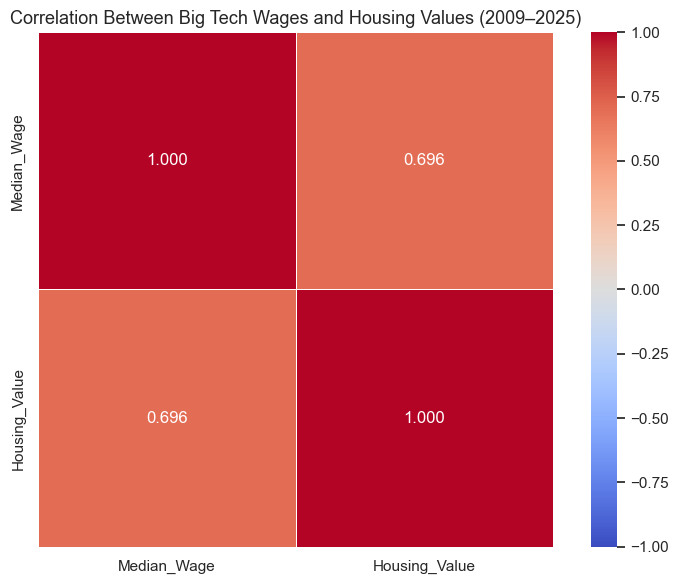

Pearson Correlation: 0.696


In [81]:
# Select variables and remove missing values
correlation_data = merged[
    ["Median_Wage", "Housing_Value"]
].dropna()

# Calculate Pearson correlation matrix
correlation = correlation_data.corr(method="pearson")

print("Correlation Matrix:")
print(correlation)

# Create correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Correlation Between Big Tech Wages and Housing Values (2009–2025)",
    fontsize=13
)

plt.tight_layout()
plt.show()

# Calculate Pearson correlation coefficient
r = correlation_data["Median_Wage"].corr(
    correlation_data["Housing_Value"]
)

print(f"Pearson Correlation: {r:.3f}")

In [82]:
# Sort dataset by city, state, and year
merged = merged.sort_values(
    ["RegionName", "State", "Year"]
).copy()

# Calculate annual housing price growth (%)
merged["Housing_Growth"] = (
    merged.groupby(["RegionName", "State"])["Housing_Value"]
    .pct_change(fill_method=None) * 100
)

# Calculate annual Big Tech wage growth (%)
merged["Wage_Growth"] = (
    merged.groupby(["RegionName", "State"])["Median_Wage"]
    .pct_change(fill_method=None) * 100
)

# Identify previous year for each city
previous_year = (
    merged.groupby(["RegionName", "State"])["Year"]
    .shift(1)
)

# Calculate difference between consecutive years
gap = merged["Year"] - previous_year

# Remove growth calculations where years are not consecutive
merged.loc[
    gap != 1,
    ["Housing_Growth", "Wage_Growth"]
] = np.nan

# Display annual growth rates
print("Annual Housing and Wage Growth:")
print(
    merged[
        ["RegionName", "Year",
         "Housing_Growth", "Wage_Growth"]
    ].head(20)
)

# Remove missing growth values
growth_data = merged.dropna(
    subset=["Housing_Growth", "Wage_Growth"]
).copy()

# Calculate overall Pearson correlation
growth_corr = growth_data["Wage_Growth"].corr(
    growth_data["Housing_Growth"]
)

print(f"\nOverall Annual Growth Correlation: {growth_corr:.3f}")

Annual Housing and Wage Growth:
   RegionName  Year  Housing_Growth  Wage_Growth
0      Austin  2009             NaN          NaN
1      Austin  2010           -1.02        -7.81
2      Austin  2011           -2.73        12.79
3      Austin  2012            2.81        -5.15
4      Austin  2013           11.81         0.00
5      Austin  2014           12.76         6.13
6      Austin  2015           11.10         1.89
7      Austin  2016            7.64         9.82
8      Austin  2017            4.86         4.00
9      Austin  2018            3.78        10.04
10     Austin  2019            3.87         4.02
11     Austin  2020            8.96        23.79
12     Austin  2021           28.93         1.67
13     Austin  2022           18.20         5.70
14     Austin  2023           -9.45        -3.95
15     Austin  2024           -4.83         6.92
16     Austin  2025           -5.94         2.14
17     Dallas  2015             NaN          NaN
18     Dallas  2016           16.62  

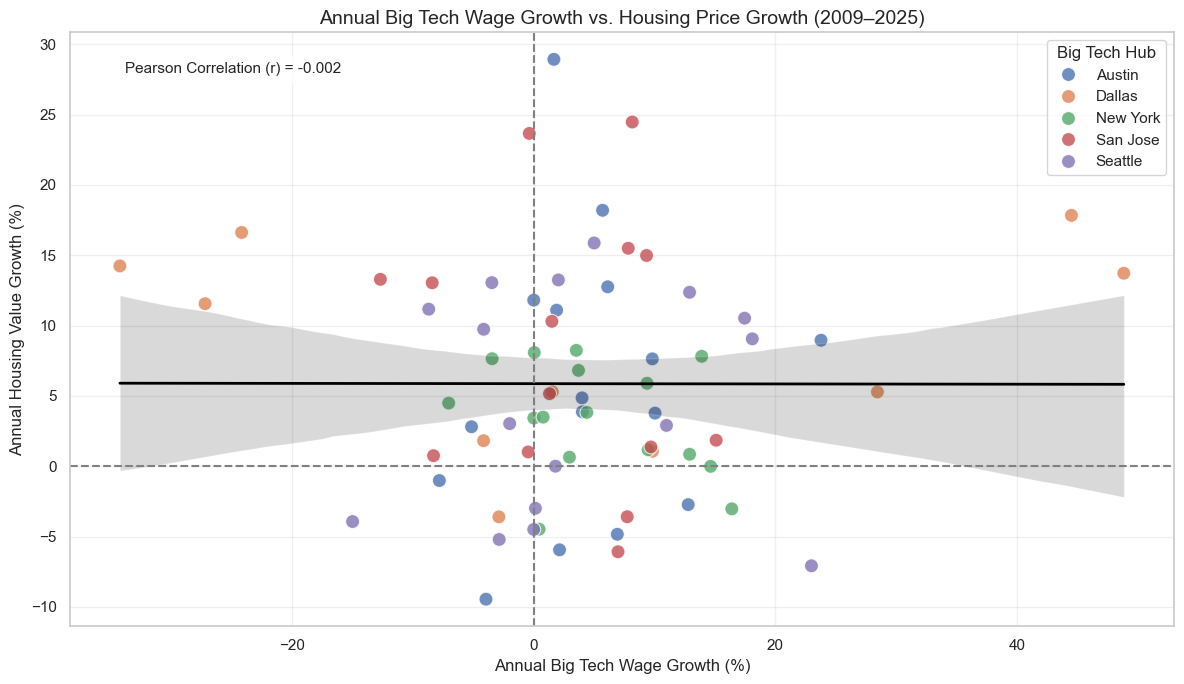

Annual Growth Correlation: -0.002


In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Pearson correlation
growth_corr = growth_data["Wage_Growth"].corr(
    growth_data["Housing_Growth"]
)

# Create scatterplot
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=growth_data,
    x="Wage_Growth",
    y="Housing_Growth",
    hue="RegionName",
    s=100,
    alpha=0.8
)

# Add regression line
sns.regplot(
    data=growth_data,
    x="Wage_Growth",
    y="Housing_Growth",
    scatter=False,
    color="black",
    line_kws={"linewidth": 2}
)

# Reference lines
plt.axhline(0, linestyle="--", color="gray")
plt.axvline(0, linestyle="--", color="gray")

# Titles and labels
plt.title(
    "Annual Big Tech Wage Growth vs. Housing Price Growth (2009–2025)",
    fontsize=14
)

plt.xlabel("Annual Big Tech Wage Growth (%)")
plt.ylabel("Annual Housing Value Growth (%)")

# Display correlation on graph
plt.text(
    0.05,
    0.95,
    f"Pearson Correlation (r) = {growth_corr:.3f}",
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend(title="Big Tech Hub")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Annual Growth Correlation: {growth_corr:.3f}")

  RegionName State  Year  Housing_Value Tech_Hub Nearby_City
0   Bellevue    WA  2009     505,921.18  Seattle    Bellevue
1   Bellevue    WA  2010     477,604.37  Seattle    Bellevue
2   Bellevue    WA  2011     444,986.18  Seattle    Bellevue
3   Bellevue    WA  2012     429,598.52  Seattle    Bellevue
4   Bellevue    WA  2013     485,391.38  Seattle    Bellevue


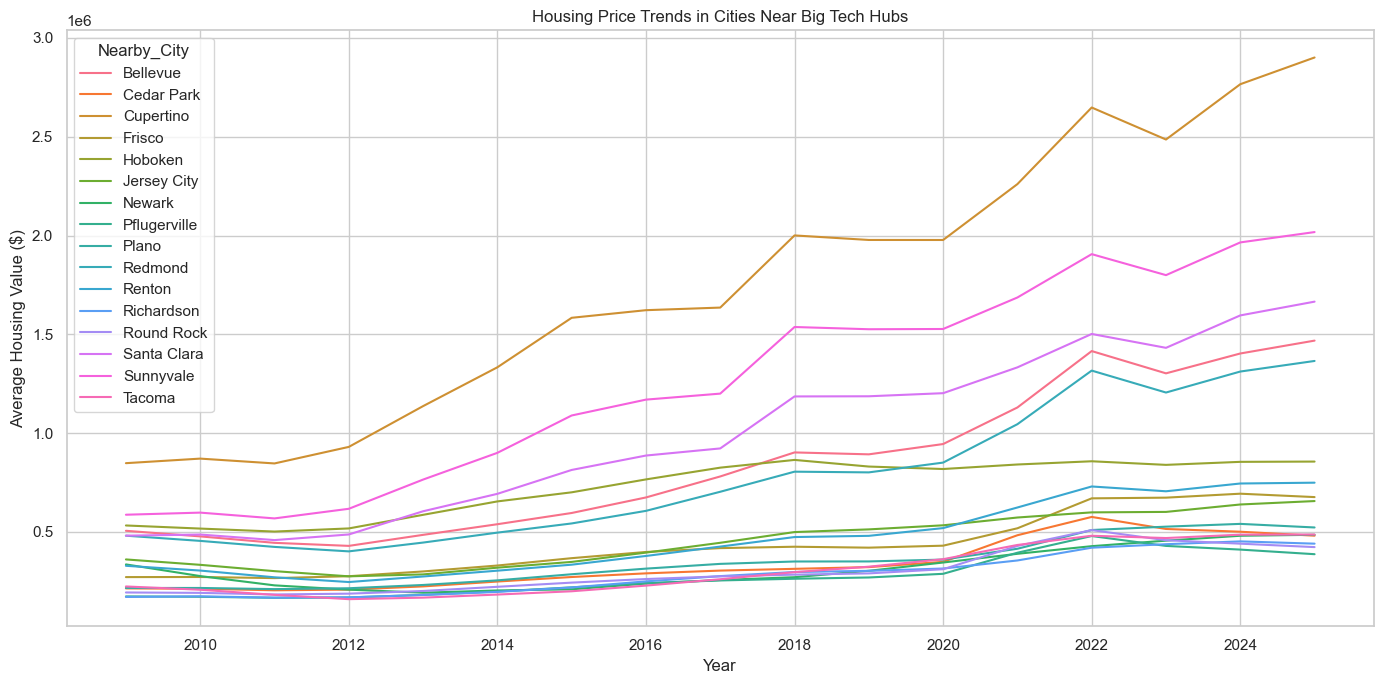

In [84]:
nearby_cities = {
    "Seattle": ["Bellevue", "Redmond", "Renton", "Tacoma"],
    "San Jose": ["Sunnyvale", "Santa Clara", "Cupertino"],
    "Austin": ["Round Rock", "Cedar Park", "Pflugerville"],
    "Dallas": ["Plano", "Frisco", "Richardson"],
    "New York": ["Jersey City", "Hoboken", "Newark"]
}

hub_states = {
    "Seattle": "WA",
    "San Jose": "CA",
    "Austin": "TX",
    "Dallas": "TX",
    "New York": "NY"
}

# Create nearby-city mapping
nearby_records = []

for hub, cities in nearby_cities.items():

    for city in cities:

        nearby_records.append({
            "Tech_Hub": hub,
            "Nearby_City": city
        })

nearby_df = pd.DataFrame(nearby_records)

# Match housing records to nearby cities.
# State filtering prevents accidental matches across states.
nearby_df["State"] = nearby_df["Tech_Hub"].map(hub_states)

# Jersey City, Hoboken, and Newark are in New Jersey
nearby_df.loc[
    nearby_df["Tech_Hub"] == "New York",
    "State"
] = "NJ"

nearby_housing = pd.merge(
    housing_annual,
    nearby_df,
    left_on=["RegionName", "State"],
    right_on=["Nearby_City", "State"],
    how="inner"
)

print(nearby_housing.head())

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=nearby_housing,
    x="Year",
    y="Housing_Value",
    hue="Nearby_City"
)

plt.title("Housing Price Trends in Cities Near Big Tech Hubs")
plt.xlabel("Year")
plt.ylabel("Average Housing Value ($)")

plt.tight_layout()
plt.show()

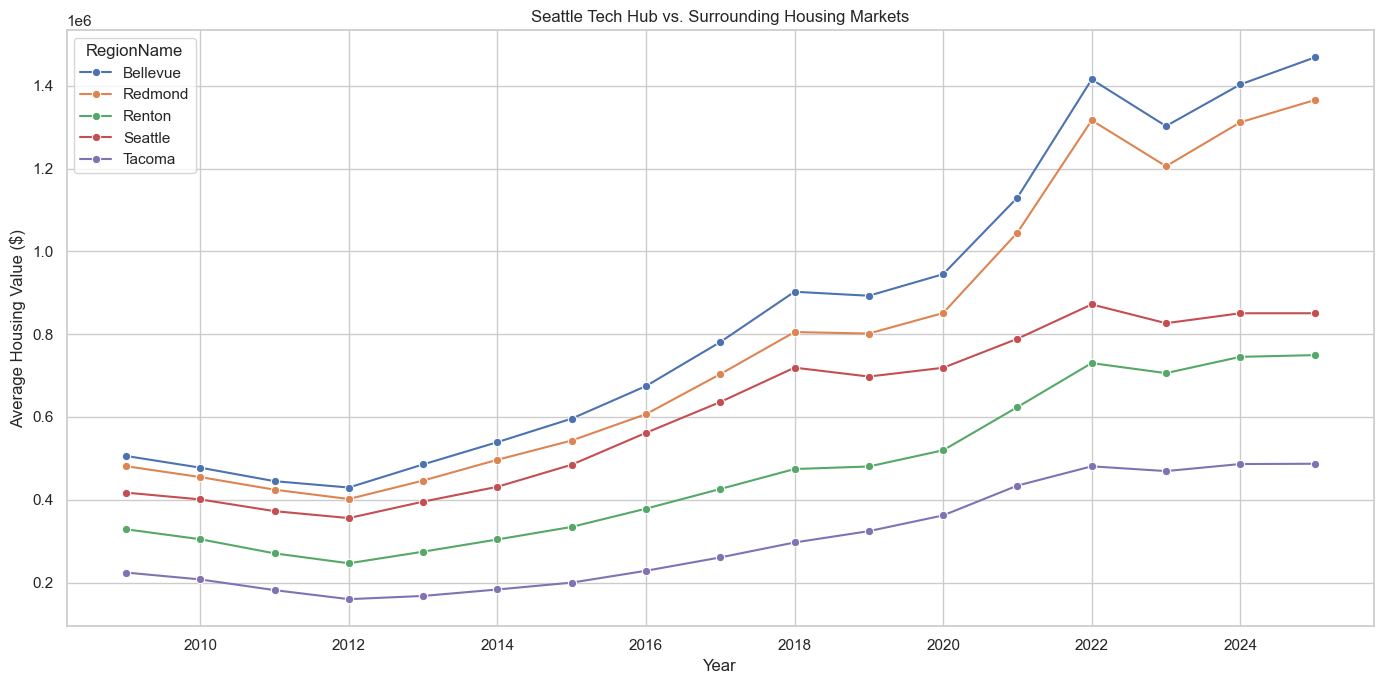

In [85]:
seattle_cities = [
    "Seattle",
    "Bellevue",
    "Redmond",
    "Renton",
    "Tacoma"
]

seattle_housing = housing_annual[
    (housing_annual["RegionName"].isin(seattle_cities))
    & (housing_annual["State"] == "WA")
]

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=seattle_housing,
    x="Year",
    y="Housing_Value",
    hue="RegionName",
    marker="o"
)

plt.title("Seattle Tech Hub vs. Surrounding Housing Markets")
plt.xlabel("Year")
plt.ylabel("Average Housing Value ($)")

plt.tight_layout()
plt.show()

In [86]:
nearby_housing = nearby_housing.sort_values(
    ["Tech_Hub", "Nearby_City", "Year"]
)

nearby_housing["Annual_Housing_Growth"] = (
    nearby_housing
    .groupby(["Tech_Hub", "Nearby_City"])["Housing_Value"]
    .pct_change(fill_method=None) * 100
)

print(
    nearby_housing[
        ["Tech_Hub", "Nearby_City",
         "Year", "Annual_Housing_Growth"]
    ].head(20)
)

growth_summary = (
    nearby_housing
    .groupby(["Tech_Hub", "Nearby_City"])
    ["Annual_Housing_Growth"]
    .mean()
    .reset_index()
)

print(growth_summary)

    Tech_Hub   Nearby_City  Year  Annual_Housing_Growth
17    Austin    Cedar Park  2009                    NaN
18    Austin    Cedar Park  2010                  -0.84
19    Austin    Cedar Park  2011                  -3.68
20    Austin    Cedar Park  2012                   1.72
21    Austin    Cedar Park  2013                   7.75
22    Austin    Cedar Park  2014                  10.96
23    Austin    Cedar Park  2015                   9.22
24    Austin    Cedar Park  2016                   6.78
25    Austin    Cedar Park  2017                   4.83
26    Austin    Cedar Park  2018                   2.91
27    Austin    Cedar Park  2019                   2.77
28    Austin    Cedar Park  2020                   8.27
29    Austin    Cedar Park  2021                  38.61
30    Austin    Cedar Park  2022                  19.16
31    Austin    Cedar Park  2023                 -10.57
32    Austin    Cedar Park  2024                  -2.69
33    Austin    Cedar Park  2025                

In [87]:
housing_annual.to_csv(
    "cleaned_housing_annual.csv",
    index=False
)

wage_annual.to_csv(
    "cleaned_bigtech_wages_annual.csv",
    index=False
)

merged.to_csv(
    "bigtech_housing_merged.csv",
    index=False
)

nearby_housing.to_csv(
    "nearby_tech_hub_housing.csv",
    index=False
)

print("EDA datasets saved successfully!")

EDA datasets saved successfully!
